In [2]:
!pip -q install plotly
import warnings, json, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
import plotly.graph_objects as go
from plotly.subplots import make_subplots
SEED = 42; os.makedirs('outputs', exist_ok=True); sns.set_theme(style='whitegrid')

In [3]:
URL = 'https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv'
try:
    df = pd.read_csv(URL, encoding='utf-8-sig')
except Exception as e:
    print('Download failed, upload the CSV manually:', e)
    from google.colab import files
    up = files.upload(); df = pd.read_csv(list(up.keys())[0], encoding='utf-8-sig')
df['Left'] = (df['Attrition'] == 'Yes').astype(int)
print(df.shape, '| overall attrition = %.1f%%' % (100*df['Left'].mean()))

(1470, 36) | overall attrition = 16.1%


## 2. Feature selection
Clustering uses **work-related numeric features** plus overtime and travel. Attrition, department and performance are **kept out** of the clustering so we can later check how the discovered groups relate to them (otherwise the analysis would be circular).

In [4]:
df['OverTimeFlag'] = (df['OverTime'] == 'Yes').astype(int)
df['TravelLevel'] = df['BusinessTravel'].map({'Non-Travel': 0, 'Travel_Rarely': 1, 'Travel_Frequently': 2})
features = ['Age','DistanceFromHome','Education','EnvironmentSatisfaction','JobInvolvement','JobLevel','JobSatisfaction','MonthlyIncome',
            'NumCompaniesWorked','RelationshipSatisfaction','StockOptionLevel','TotalWorkingYears','TrainingTimesLastYear','WorkLifeBalance',
            'YearsAtCompany','YearsInCurrentRole','YearsSinceLastPromotion','YearsWithCurrManager','OverTimeFlag','TravelLevel']
X = df[features]; Xs = StandardScaler().fit_transform(X)
print(len(features), 'features used for clustering')

20 features used for clustering


## 3. PCA – reduce dimensions

Components for 80% variance: 12 | for 90%: 14 | original: 20


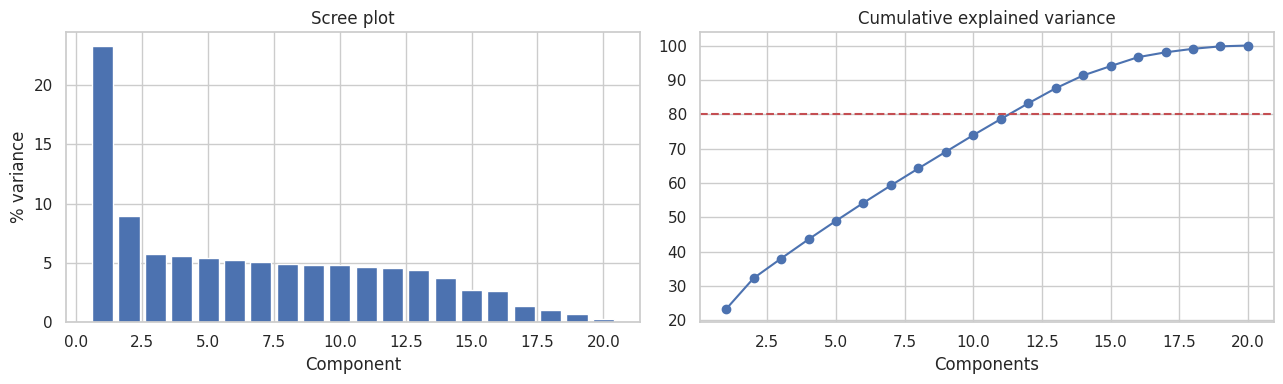

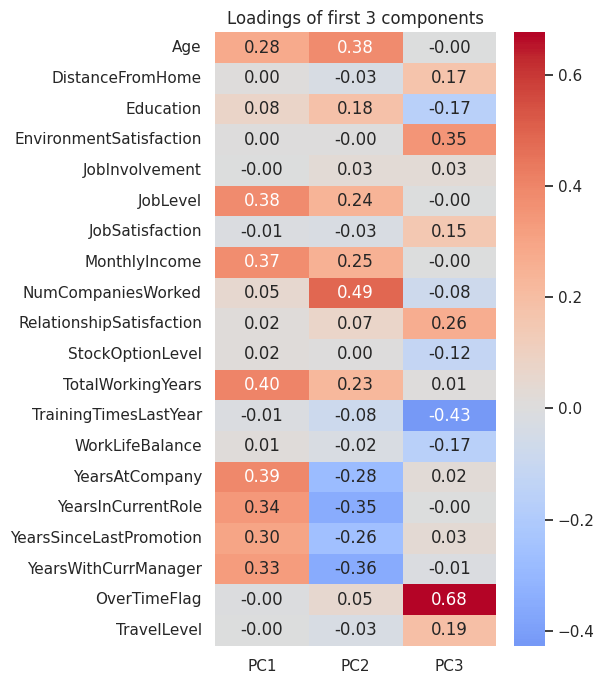

PC1 top features: ['TotalWorkingYears', 'YearsAtCompany', 'JobLevel', 'MonthlyIncome'] | 23.3% variance
PC2 top features: ['NumCompaniesWorked', 'Age', 'YearsWithCurrManager', 'YearsInCurrentRole'] | 9.0% variance
PC3 top features: ['OverTimeFlag', 'TrainingTimesLastYear', 'EnvironmentSatisfaction', 'RelationshipSatisfaction'] | 5.7% variance


In [5]:
pca_full = PCA(random_state=SEED).fit(Xs)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n80, n90 = int(np.argmax(cum >= 0.80)) + 1, int(np.argmax(cum >= 0.90)) + 1
print(f'Components for 80% variance: {n80} | for 90%: {n90} | original: {len(features)}')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, len(cum)+1), pca_full.explained_variance_ratio_*100); ax[0].set_title('Scree plot'); ax[0].set_xlabel('Component'); ax[0].set_ylabel('% variance')
ax[1].plot(range(1, len(cum)+1), cum*100, marker='o'); ax[1].axhline(80, color='r', ls='--'); ax[1].set_title('Cumulative explained variance'); ax[1].set_xlabel('Components')
plt.tight_layout(); plt.savefig('outputs/pca_variance.png', dpi=130); plt.show()

pca = PCA(n_components=n80, random_state=SEED); Z = pca.fit_transform(Xs)
loadings = pd.DataFrame(pca.components_[:3].T, index=features, columns=['PC1','PC2','PC3'])
loadings.round(3).to_csv('outputs/pca_loadings.csv')
plt.figure(figsize=(6, 7)); sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Loadings of first 3 components')
plt.tight_layout(); plt.savefig('outputs/pca_loadings.png', dpi=130); plt.show()
for i in range(3): print(f'PC{i+1} top features:', loadings.iloc[:, i].abs().sort_values(ascending=False).head(4).index.tolist(), '| %.1f%% variance' % (pca.explained_variance_ratio_[i]*100))

## 4. K-Means – choosing k

      inertia  silhouette  davies_bouldin
k                                        
2   19899.852       0.195           1.946
3   18337.815       0.126           2.285
4   17201.722       0.118           2.210
5   16400.482       0.102           2.370
6   15894.190       0.099           2.302
7   15497.688       0.093           2.357
8   15144.542       0.089           2.317
9   14844.979       0.086           2.275
10  14577.552       0.084           2.382


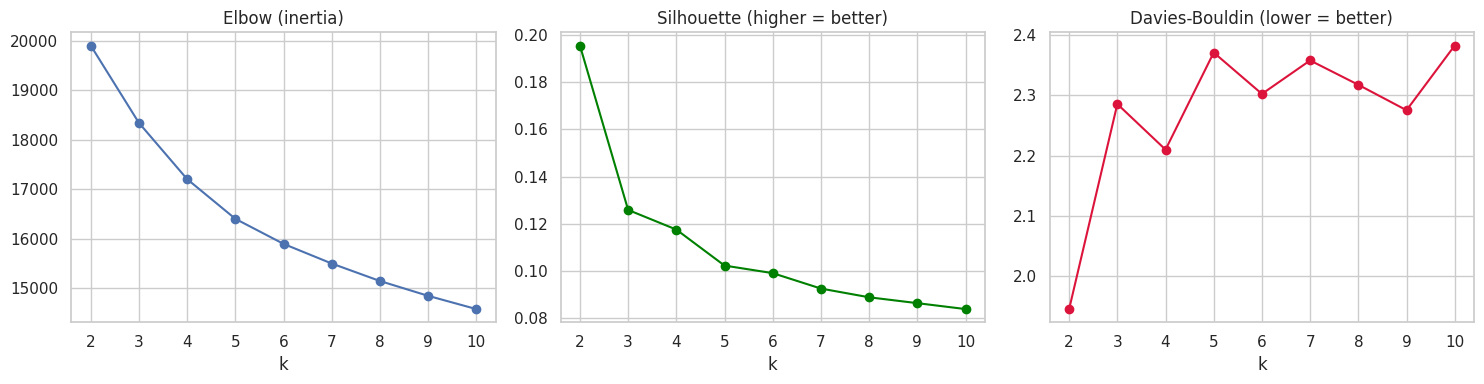

In [6]:
ks = range(2, 11); inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_)); dbi.append(davies_bouldin_score(Z, km.labels_))
sel = pd.DataFrame({'k': list(ks), 'inertia': inertia, 'silhouette': sil, 'davies_bouldin': dbi}).set_index('k'); sel.round(3).to_csv('outputs/kmeans_selection.csv'); print(sel.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(list(ks), inertia, marker='o'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(list(ks), sil, marker='o', color='green'); ax[1].set_title('Silhouette (higher = better)')
ax[2].plot(list(ks), dbi, marker='o', color='crimson'); ax[2].set_title('Davies-Bouldin (lower = better)')
for a in ax: a.set_xlabel('k')
plt.tight_layout(); plt.savefig('outputs/kmeans_selection.png', dpi=130); plt.show()

In [7]:
# Choose k: best silhouette between 3 and 6 (at least 3 groups are needed for a useful segmentation)
K = int(sel.loc[3:6, 'silhouette'].idxmax()); print('Chosen k =', K)
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Z); df['KMeans'] = km.labels_
print('Silhouette = %.3f | Davies-Bouldin = %.3f' % (silhouette_score(Z, km.labels_), davies_bouldin_score(Z, km.labels_)))
print(df['KMeans'].value_counts().sort_index())

Chosen k = 3
Silhouette = 0.126 | Davies-Bouldin = 2.284
KMeans
0    835
1    414
2    221
Name: count, dtype: int64


## 5. Hierarchical clustering (Ward linkage)

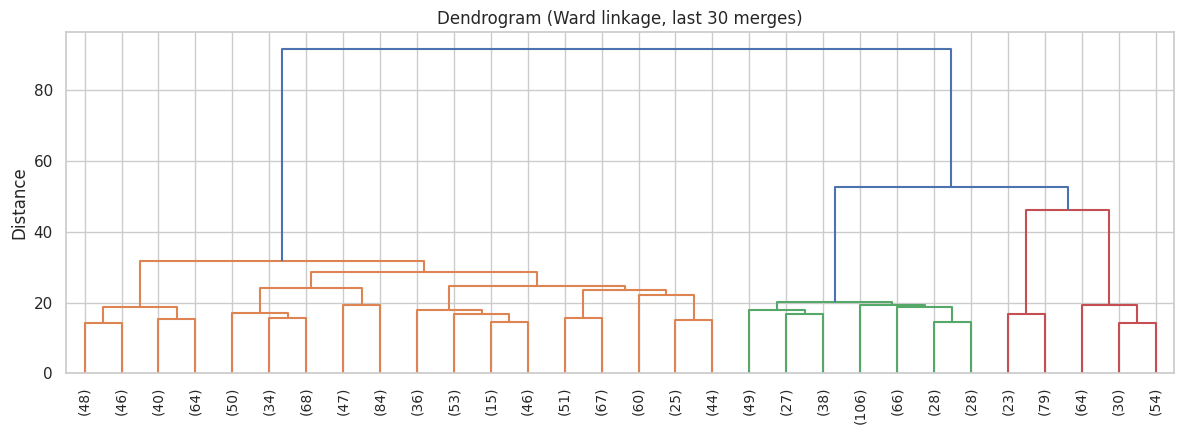

Hierarchical: silhouette = 0.105 | Davies-Bouldin = 2.484
Agreement with K-Means (Adjusted Rand Index) = 0.753


Hier,0,1,2
KMeans,,,
0,19,808,8
1,26,68,320
2,205,2,14


In [8]:
Lk = linkage(Z, method='ward')
plt.figure(figsize=(12, 4.5)); dendrogram(Lk, truncate_mode='lastp', p=30, leaf_rotation=90, no_labels=False, color_threshold=Lk[-(K-1), 2])
plt.title('Dendrogram (Ward linkage, last 30 merges)'); plt.ylabel('Distance'); plt.tight_layout(); plt.savefig('outputs/dendrogram.png', dpi=130); plt.show()
hc = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Z); df['Hier'] = hc.labels_
print('Hierarchical: silhouette = %.3f | Davies-Bouldin = %.3f' % (silhouette_score(Z, hc.labels_), davies_bouldin_score(Z, hc.labels_)))
ari = adjusted_rand_score(df['KMeans'], df['Hier']); print('Agreement with K-Means (Adjusted Rand Index) = %.3f' % ari)
pd.crosstab(df['KMeans'], df['Hier'], rownames=['KMeans'], colnames=['Hier'])

## 6. Cluster profiles (K-Means)
**Edit the `NAMES` dictionary after you read the profile table** so every segment has a business-friendly name.

In [9]:
prof = df.groupby('KMeans').agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: 100*s.mean()), Age=('Age','mean'), MonthlyIncome=('MonthlyIncome','mean'),
        JobLevel=('JobLevel','mean'), TotalWorkingYears=('TotalWorkingYears','mean'), YearsAtCompany=('YearsAtCompany','mean'), OverTime_pct=('OverTimeFlag', lambda s: 100*s.mean()),
        JobSatisfaction=('JobSatisfaction','mean'), WorkLifeBalance=('WorkLifeBalance','mean'), Performance=('PerformanceRating','mean'), TravelLevel=('TravelLevel','mean')).round(2)
prof.to_csv('outputs/cluster_profiles.csv'); prof

,Employees,Attrition_pct,Age,MonthlyIncome,JobLevel,TotalWorkingYears,YearsAtCompany,OverTime_pct,JobSatisfaction,WorkLifeBalance,Performance,TravelLevel
KMeans,,,,,,,,,,,,
0,835,21.32,34.28,4269.85,1.51,7.19,3.40,30.18,2.72,2.75,3.14,1.09
1,414,9.90,36.23,6229.89,2.11,11.88,10.31,24.15,2.79,2.79,3.18,1.06
2,221,8.14,48.22,15451.63,4.07,25.60,14.45,28.96,2.66,2.76,3.14,1.12


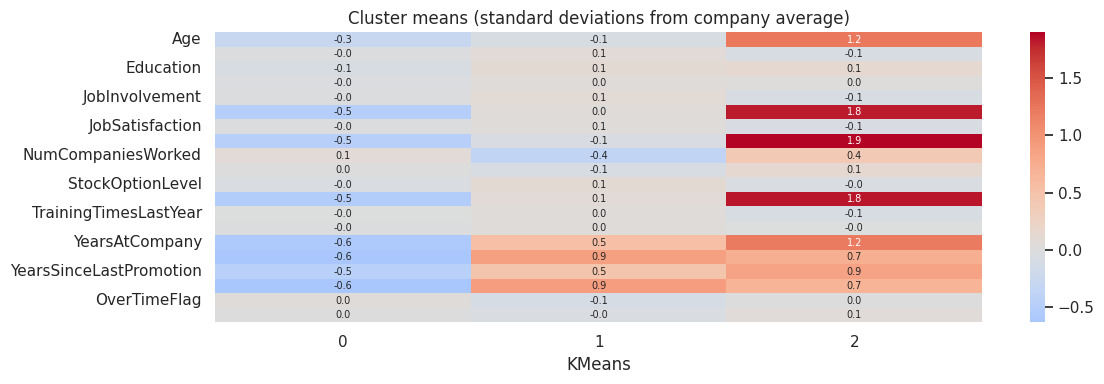

In [10]:
z = (df.groupby('KMeans')[features].mean() - df[features].mean()) / df[features].std()
plt.figure(figsize=(12, 4)); sns.heatmap(z.T, cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7}); plt.title('Cluster means (standard deviations from company average)')
plt.tight_layout(); plt.savefig('outputs/cluster_heatmap.png', dpi=130); plt.show()
z.round(2).to_csv('outputs/cluster_zscores.csv')

In [11]:
# >>> EDIT AFTER READING THE PROFILE TABLE <<<
NAMES = {i: f'Segment {i}' for i in range(K)}
if K == 3:   # auto-name by income rank so labels stay correct even if cluster ids change between runs
    order = df.groupby('KMeans')['MonthlyIncome'].mean().sort_values().index.tolist()
    NAMES = {order[0]: 'Early-Career Core', order[1]: 'Established Mid-Career', order[2]: 'Senior Experts'}
df['Segment'] = df['KMeans'].map(NAMES)

## 7. PCA visualisation of employee groups

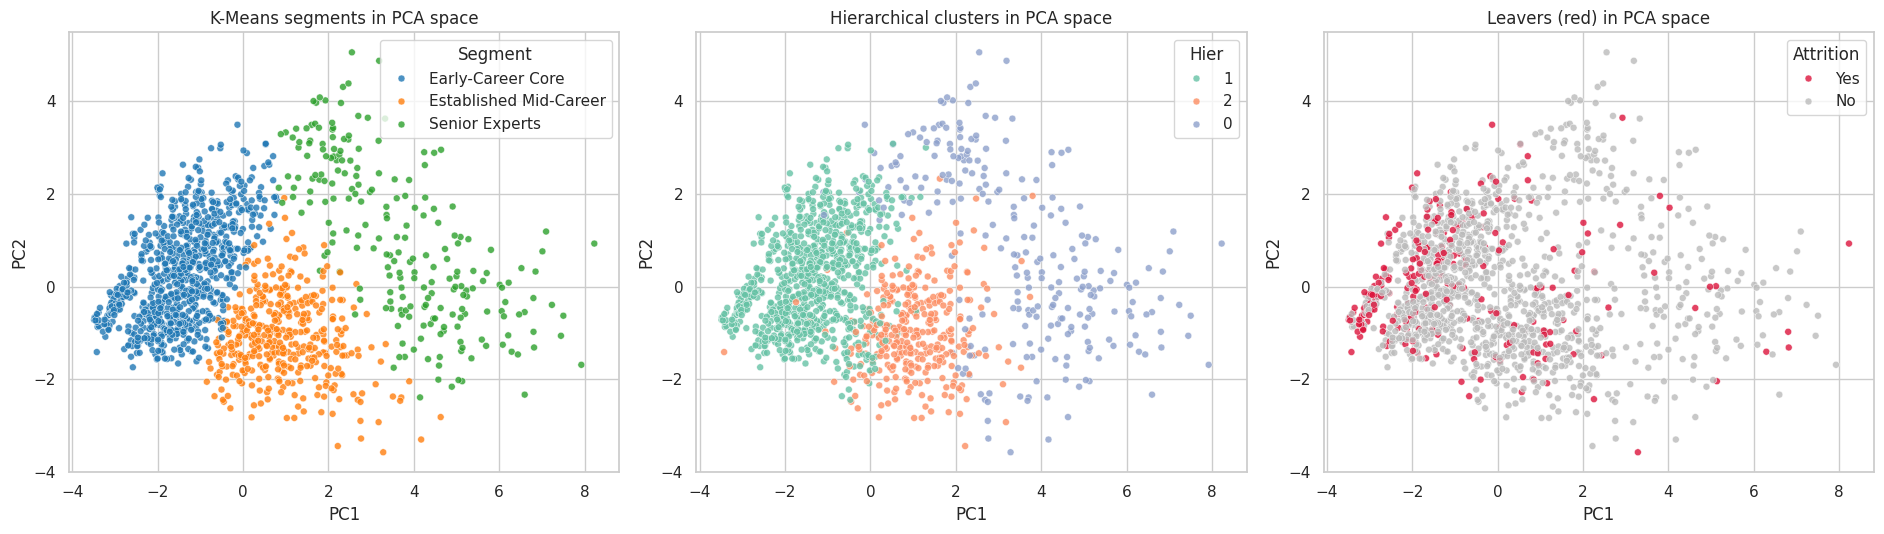

In [12]:
pc = pd.DataFrame(Z[:, :3], columns=['PC1','PC2','PC3']); pc['Segment'] = df['Segment'].values; pc['Attrition'] = df['Attrition'].values
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
sns.scatterplot(data=pc, x='PC1', y='PC2', hue='Segment', palette='tab10', s=25, alpha=0.8, ax=ax[0]); ax[0].set_title('K-Means segments in PCA space')
sns.scatterplot(data=pc, x='PC1', y='PC2', hue=df['Hier'].astype(str), palette='Set2', s=25, alpha=0.8, ax=ax[1]); ax[1].set_title('Hierarchical clusters in PCA space')
sns.scatterplot(data=pc, x='PC1', y='PC2', hue='Attrition', palette={'No': '#bbbbbb', 'Yes': 'crimson'}, s=25, alpha=0.8, ax=ax[2]); ax[2].set_title('Leavers (red) in PCA space')
plt.tight_layout(); plt.savefig('outputs/pca_clusters.png', dpi=130); plt.show()

## 8. High-risk employee clusters

In [13]:
overall = 100*df['Left'].mean()
risk = df.groupby('Segment').agg(Employees=('Left','size'), Leavers=('Left','sum'), Attrition_pct=('Left', lambda s: 100*s.mean())).round(1)
risk['Risk_ratio'] = (risk['Attrition_pct'] / overall).round(2)
risk['Flag'] = np.where(risk['Risk_ratio'] >= 1.25, 'HIGH RISK', np.where(risk['Risk_ratio'] <= 0.75, 'Low risk', 'Average'))
risk = risk.sort_values('Attrition_pct', ascending=False); risk.to_csv('outputs/high_risk_clusters.csv'); print('Overall attrition: %.1f%%' % overall); risk

Overall attrition: 16.1%


,Employees,Leavers,Attrition_pct,Risk_ratio,Flag
Segment,,,,,
Early-Career Core,835,178,21.3,1.32,HIGH RISK
Established Mid-Career,414,41,9.9,0.61,Low risk
Senior Experts,221,18,8.1,0.50,Low risk


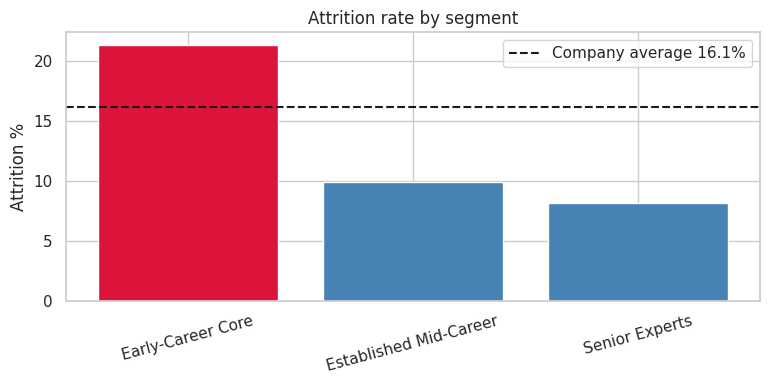

In [14]:
plt.figure(figsize=(8, 4)); colors = ['crimson' if f == 'HIGH RISK' else 'steelblue' for f in risk['Flag']]
plt.bar(risk.index, risk['Attrition_pct'], color=colors); plt.axhline(overall, color='k', ls='--', label=f'Company average {overall:.1f}%'); plt.ylabel('Attrition %'); plt.legend()
plt.title('Attrition rate by segment'); plt.xticks(rotation=15); plt.tight_layout(); plt.savefig('outputs/attrition_by_segment.png', dpi=130); plt.show()

## 9. Department-level workforce segments

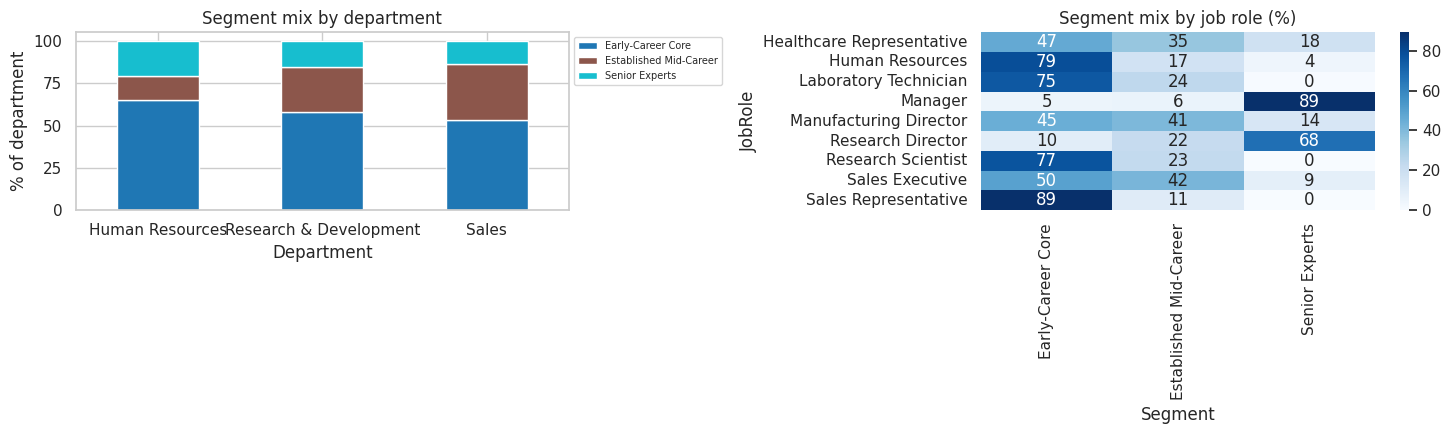

Segment,Early-Career Core,Established Mid-Career,Senior Experts
Department,,,
Human Resources,65.1,14.3,20.6
Research & Development,57.8,27.0,15.3
Sales,53.6,32.7,13.7


,Employees,Attrition_pct
Department,,
Human Resources,63,19.0
Research & Development,961,13.8
Sales,446,20.6


In [15]:
dep = pd.crosstab(df['Department'], df['Segment'], normalize='index').mul(100).round(1); dep.to_csv('outputs/department_segments.csv')
dep_attr = df.groupby('Department')['Left'].agg(['size', lambda s: 100*s.mean()]).round(1); dep_attr.columns = ['Employees', 'Attrition_pct']; dep_attr.to_csv('outputs/department_attrition.csv')
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
dep.plot(kind='bar', stacked=True, ax=ax[0], colormap='tab10'); ax[0].set_ylabel('% of department'); ax[0].set_title('Segment mix by department'); ax[0].tick_params(axis='x', rotation=0); ax[0].legend(fontsize=7, bbox_to_anchor=(1, 1))
role = pd.crosstab(df['JobRole'], df['Segment'], normalize='index').mul(100); sns.heatmap(role, annot=True, fmt='.0f', cmap='Blues', ax=ax[1]); ax[1].set_title('Segment mix by job role (%)')
plt.tight_layout(); plt.savefig('outputs/department_segments.png', dpi=130); plt.show(); display(dep); display(dep_attr)

## 10. Performance groups

In [16]:
df['PerfGroup'] = df['PerformanceRating'].map({3: 'Excellent (3)', 4: 'Outstanding (4)'})
perf_attr = df.groupby('PerfGroup').agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: 100*s.mean()), AvgIncome=('MonthlyIncome','mean'), AvgHike=('PercentSalaryHike','mean')).round(1)
perf_seg = pd.crosstab(df['Segment'], df['PerfGroup'], normalize='index').mul(100).round(1)
perf_attr.to_csv('outputs/performance_groups.csv'); perf_seg.to_csv('outputs/performance_by_segment.csv'); display(perf_attr); display(perf_seg)
# Regretted attrition: high performers who left
hp_left = df[(df['PerformanceRating'] == 4) & (df['Left'] == 1)].groupby('Segment').size(); print('Outstanding performers who left, by segment:\n', hp_left)

,Employees,Attrition_pct,AvgIncome,AvgHike
PerfGroup,,,,
Excellent (3),1244,16.1,6537.3,14.0
Outstanding (4),226,16.4,6313.9,21.8


PerfGroup,Excellent (3),Outstanding (4)
Segment,,
Early-Career Core,85.6,14.4
Established Mid-Career,82.1,17.9
Senior Experts,85.5,14.5


Outstanding performers who left, by segment:
 Segment
Early-Career Core         27
Established Mid-Career    10
dtype: int64


## 11. Retention-risk groups
Each segment is assigned a tier from its attrition rate relative to the company average:  **High** (≥ 1.25×), **Low** (≤ 0.75×), otherwise **Medium**. Employees inherit the tier of their segment and we then check how many actually left.

In [17]:
tier_map = {s: ('High' if f == 'HIGH RISK' else 'Low' if f == 'Low risk' else 'Medium') for s, f in risk['Flag'].items()}
df['RiskTier'] = df['Segment'].map(tier_map)
tiers = df.groupby('RiskTier').agg(Employees=('Left','size'), Leavers=('Left','sum'), Attrition_pct=('Left', lambda s: 100*s.mean())).round(1).reindex(['High','Medium','Low']).dropna(); tiers.to_csv('outputs/retention_risk_groups.csv'); display(tiers)
share = 100 * tiers.loc['High', 'Leavers'] / df['Left'].sum() if 'High' in tiers.index else 0
print('High-risk tier holds %.1f%% of all leavers while being %.1f%% of staff' % (share, 100*tiers.loc['High','Employees']/len(df) if 'High' in tiers.index else 0))

,Employees,Leavers,Attrition_pct
RiskTier,,,
High,835.0,178.0,21.3
Low,635.0,59.0,9.3


High-risk tier holds 75.1% of all leavers while being 56.8% of staff


## 12. Workforce Analytics Dashboard (interactive HTML)

In [18]:
COL = px_colors = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b']
segs = sorted(df['Segment'].unique()); cmap = {s: COL[i % 6] for i, s in enumerate(segs)}
fig = make_subplots(rows=3, cols=3, specs=[[{'colspan': 2, 'type': 'xy'}, None, {'type': 'xy'}], [{'type': 'xy'}, {'type': 'xy'}, {'type': 'xy'}], [{'type': 'xy'}, {'type': 'xy'}, {'type': 'xy'}]],
    subplot_titles=('Employee segments (PCA view)', 'Segment size', 'Attrition % by segment', 'Segment mix by department', 'Retention-risk groups', 'Avg monthly income by segment', 'Overtime % by segment', 'Outstanding performers (%)'),
    vertical_spacing=0.12, horizontal_spacing=0.07)
for s in segs:
    m = df['Segment'] == s
    fig.add_trace(go.Scatter(x=Z[m.values, 0], y=Z[m.values, 1], mode='markers', name=s, marker=dict(color=cmap[s], size=5, opacity=0.7), legendgroup=s, text=df.loc[m, 'JobRole'], hovertemplate='%{text}<extra>'+s+'</extra>'), row=1, col=1)
sz = df['Segment'].value_counts().reindex(segs); fig.add_trace(go.Bar(x=segs, y=sz.values, marker_color=[cmap[s] for s in segs], showlegend=False), row=1, col=3)
at = df.groupby('Segment')['Left'].mean().mul(100).reindex(segs).round(1); fig.add_trace(go.Bar(x=segs, y=at.values, marker_color=[cmap[s] for s in segs], showlegend=False, text=at.values, textposition='outside'), row=2, col=1)
fig.add_hline(y=overall, line_dash='dash', row=2, col=1)
for s in segs: fig.add_trace(go.Bar(x=dep.index, y=dep[s] if s in dep else 0, name=s, marker_color=cmap[s], showlegend=False), row=2, col=2)
fig.update_layout(barmode='stack')
tr = tiers['Attrition_pct']; fig.add_trace(go.Bar(x=tr.index, y=tr.values, marker_color=['crimson' if t == 'High' else 'gold' if t == 'Medium' else 'seagreen' for t in tr.index], showlegend=False, text=tr.values, textposition='outside'), row=2, col=3)
inc = df.groupby('Segment')['MonthlyIncome'].mean().reindex(segs).round(0); fig.add_trace(go.Bar(x=segs, y=inc.values, marker_color=[cmap[s] for s in segs], showlegend=False), row=3, col=1)
ot = df.groupby('Segment')['OverTimeFlag'].mean().mul(100).reindex(segs).round(1); fig.add_trace(go.Bar(x=segs, y=ot.values, marker_color=[cmap[s] for s in segs], showlegend=False), row=3, col=2)
pf = df.groupby('Segment')['PerformanceRating'].apply(lambda s: 100*(s == 4).mean()).reindex(segs).round(1); fig.add_trace(go.Bar(x=segs, y=pf.values, marker_color=[cmap[s] for s in segs], showlegend=False), row=3, col=3)
fig.update_layout(height=1050, title=dict(text=f'<b>Workforce Analytics Dashboard</b> – {len(df):,} employees · {overall:.1f}% attrition · {K} segments', x=0.01), template='plotly_white', legend=dict(orientation='h', y=1.07, x=0.3))
fig.update_xaxes(tickfont=dict(size=9)); fig.write_html('Workforce_Analytics_Dashboard.html', include_plotlyjs=True); fig.show()

## 13. Save results

In [19]:
df[['EmployeeNumber','Department','JobRole','Attrition','KMeans','Hier','Segment','RiskTier']].to_csv('outputs/employee_segments.csv', index=False)
summary = dict(k=K, n80=n80, n90=n90, n_features=len(features), var_pc=[float(v) for v in pca.explained_variance_ratio_[:3]], cum80=float(cum[n80-1]),
               sil_km=float(silhouette_score(Z, km.labels_)), dbi_km=float(davies_bouldin_score(Z, km.labels_)), sil_hc=float(silhouette_score(Z, hc.labels_)), dbi_hc=float(davies_bouldin_score(Z, hc.labels_)),
               ari=float(ari), overall_attrition=float(overall), names=NAMES)
json.dump(summary, open('outputs/summary.json', 'w'), indent=2); print(summary)

{'k': 3, 'n80': 12, 'n90': 14, 'n_features': 20, 'var_pc': [0.23271629691039616, 0.08988081293449628, 0.05717286808816444], 'cum80': 0.8315598784499746, 'sil_km': 0.125813555235351, 'dbi_km': 2.284152436993943, 'sil_hc': 0.10543795604087321, 'dbi_hc': 2.4838585793476837, 'ari': 0.7533842374302748, 'overall_attrition': 16.122448979591837, 'names': {0: 'Early-Career Core', 1: 'Established Mid-Career', 2: 'Senior Experts'}}
